<a href="https://colab.research.google.com/github/farroyogutierrez/dmml_translator_project/blob/main/project3_arroyo_gutierrez.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### csc 4422
### project 3: german -> english, english -> german machine translator
### j. f. arroyo g.
### 05/14/26

My project I don't think is complete, but is nearly there. The old dataset that I used was horrendous, but the new one is a lot better. So, I think with a bit more tweaking, it could be better. This can be done by using more rows, using more dimensions, maybe use more epochs, etc. I made very minimal changes when it comes to using the old dataset and the new one, so I believe if I found a better dataset than the new one, it could improve the translator's capabilities. Overall, with more time, this translator can be better.

# Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
import tensorflow as tf

In [ ]:
pd.set_option('display.max_colwidth', None)

## Old Data

No need to use, just for archival purposes :)

original training dataset is too large to import normally, using gdown to download the dataset and then grab the first X rows, more than X yields OOM error

option #1 download the dataset from public drive

note: too many runs of this option temporaraly locks you from running the code as google doesn't like it when you download a file from drive too many times within 24 hours, every run of this option will redownload the .csv, recommended for when you don't feel like doing option #2, which requires downloading the .csv from kaggle and uploading it directly to this notebook

In [ ]:
# import gdown
# file_id = "1yBPgzymtGl3p-RZ8gvL_-oxvBfcgZ_j6"
# url     = f"https://drive.google.com/uc?id={file_id}"
# gdown.download(url, "wmt14_translate_de-en_train.csv", quiet=False)

# df = pd.read_csv("wmt14_translate_de-en_train.csv", nrows=20000)
# df.head(10)

option #2 upload dataset and run from file path

note: requires you to download the dataset from kaggle and upload it, recommended when running code several times in a row, as it doesn't need to download the .csv everytime the notebook is ran, which is quicker as the .csv is >1GB in size

dataset: https://www.kaggle.com/datasets/mohamedlotfy50/wmt-2014-english-german

In [ ]:
# file_path = "/content/wmt14_translate_de-en_train.csv"

# df = pd.read_csv(file_path, nrows=20000)
# df.head(10)

## New Data

Note: Works best, in order to use this dataset, you must select German and English sentences from Tatoeba's download page. For ease I have uploaded it to my google drive.

Download location: https://tatoeba.org/en/downloads

In [ ]:
file_path = 'https://drive.google.com/uc?export=download&id=1ytqg6AcfTSgUmIEAId4Q6ZD1LohQbxXi'

df = pd.read_csv(file_path, sep='\t')

df['de'] = df['Lass uns etwas versuchen!']
df['en'] = df["Let's try something."]

df = df[['en', 'de']].head(50000)
# df = df[['en', 'de']].head(100000)

df.head(10)

,en,de
0,Let's try something.,Lasst uns etwas ausprobieren!
1,Let's try something.,Lass uns mal was ausprobieren.
2,Today is June 18th and it is Muiriel's birthday!,Heute ist der 18. Juni und das ist der Geburtstag von Muiriel!
3,Today is June 18th and it is Muiriel's birthday!,Heute ist der achtzehnte Juni — und Muiriels Geburtstag!
4,Muiriel is 20 now.,Muiriel ist jetzt 20.
5,"The password is ""Muiriel"".","Das Passwort ist ""Muiriel""."
6,"The password is ""Muiriel"".",Das Passwort lautet „Muiriel“.
7,"The password is ""Muiriel"".",Das Kennwort lautet „Muiriel“.
8,I will be back soon.,Ich werde bald zurück sein.
9,I will be back soon.,Bin gleich zurück.


# Investigation and Cleaning

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   en      50000 non-null  object
 1   de      50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [ ]:
df.nunique()

,0
en,40882
de,49095


drop all the NaNs and reset the index

In [ ]:
df = df.dropna(subset=["en", "de"])
df = df.reset_index(drop=True)

add start and end to sentences so when we tokenize and predict, the translator knows when to start the translation process, and when to end the translation process

In [ ]:
for i in range(len(df)):
    df.loc[i, "en"] = "<start> " + df.loc[i, "en"] + " <end>"
    df.loc[i, "de"] = "<start> " + df.loc[i, "de"] + " <end>"

# Model Building

## Vectorize

In [ ]:
de_vectorizer = tf.keras.layers.TextVectorization(
    standardize="lower_and_strip_punctuation",
    output_mode="int"
)

de_vectorizer.adapt(df["de"])

de_vocab = de_vectorizer.get_vocabulary()
de_vocab_size = len(de_vocab)

In [ ]:
en_vectorizer = tf.keras.layers.TextVectorization(
    standardize="lower_and_strip_punctuation",
    output_mode="int"
)

en_vectorizer.adapt(df["en"])

en_vocab = en_vectorizer.get_vocabulary()
en_vocab_size = len(en_vocab)

create look-up dictionaries for both languages

German Dictionary

In [ ]:
de_word_to_index = {}
for i, word in enumerate(de_vocab):
    de_word_to_index[word] = i

de_index_to_word = {}
for i, word in enumerate(de_vocab):
    de_index_to_word[i] = word

print(f"german vocab size:  {de_vocab_size}")
# print(f"german vocab: {de_word_to_index}")

german vocab size:  21169


English Disctionary

In [ ]:
en_word_to_index = {}
for i, word in enumerate(en_vocab):
    en_word_to_index[word] = i

en_index_to_word = {}
for i, word in enumerate(en_vocab):
    en_index_to_word[i] = word

print(f"englsih vocab size: {en_vocab_size}")
# print(f"english vocab: {en_word_to_index}")

englsih vocab size: 11578


## Training Prep

convert columns to numpy, vectorize, turn back to numpy to use split later on

In [ ]:
de_sequences = de_vectorizer(np.array(df["de"])).numpy()

In [ ]:
en_sequences = en_vectorizer(np.array(df["en"])).numpy()

find the max array shape to avoid shape mismatch error

In [ ]:
max_len = max(de_sequences.shape[1], en_sequences.shape[1])

pad the arrays with 0s so they're all the same length (by using the previously found max_len)

In [ ]:
de_sequences = tf.keras.preprocessing.sequence.pad_sequences(de_sequences, maxlen=max_len, padding="post")

print(f"german sequences shape: {de_sequences.shape}")

german sequences shape: (50000, 76)


In [ ]:
en_sequences = tf.keras.preprocessing.sequence.pad_sequences(en_sequences, maxlen=max_len, padding="post")

print(f"english sequences shape: {en_sequences.shape}")

english sequences shape: (50000, 76)


In [ ]:
# window_size = 3

# Training

drop the first and last token as we don't want to predict those as they are our start and end tokens

german to english

In [ ]:
X_de = de_sequences[:, :-1]
y_en = en_sequences[:, 1:]

english to german

In [ ]:
X_en = en_sequences[:, :-1]
y_de = de_sequences[:, 1:]

In [ ]:
de_train, de_test, y_en_train, y_en_test = train_test_split(X_de, y_en, test_size=0.2, random_state=1)
en_train, en_test, y_de_train, y_de_test = train_test_split(X_en, y_de, test_size=0.2, random_state=1)

return back to tf, as it prefers its own variable type

In [ ]:
de_train = tf.Variable(de_train)
y_en_train = tf.Variable(y_en_train)
de_test = tf.Variable(de_test)
y_en_test = tf.Variable(y_en_test)

In [ ]:
en_train = tf.Variable(en_train)
y_de_train = tf.Variable(y_de_train)
en_test = tf.Variable(en_test)
y_de_test = tf.Variable(y_de_test)

## Models

each model will have three layers, embedding, LSTM, and dense

embedding = turns word indexes into float vectors

LSTM = builds context

dense = scores english word

metrics = percentage of word predictions that are correct

since i am training two models, i will use the same hyperparameters, however, the english to german model trains better so its hyperparameters should be different than the german to english model but for now, they will be the same

embedding_dim = number of numbers used to represent each word as a vector
hidden_dim = number of numbers making up the LSTM's internal memory

note: higher numbers uses more memory (risk of OOM error), but yields better results

In [ ]:
embedding_dim = 64
hidden_dim = 64

In [ ]:
learning_rates = 0.01

german to english model

In [ ]:
de_en_model = tf.keras.models.Sequential([
    tf.keras.layers.Embedding(input_dim=de_vocab_size, output_dim=embedding_dim, mask_zero=True, name="de_embedding"),
    tf.keras.layers.LSTM(hidden_dim, return_sequences=True),
    tf.keras.layers.Dense(en_vocab_size, activation="softmax")
])

In [ ]:
de_en_model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rates),
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [ ]:
# de_en_model.summary()

english to german model

In [ ]:
en_de_model = tf.keras.models.Sequential([
    tf.keras.layers.Embedding(input_dim=en_vocab_size, output_dim=embedding_dim, mask_zero=True, name="en_embedding"),
    tf.keras.layers.LSTM(hidden_dim, return_sequences=True),
    tf.keras.layers.Dense(de_vocab_size, activation="softmax")
])

In [ ]:
en_de_model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rates),
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [ ]:
# en_de_model.summary()

speed improvements:

    -pair each input with its target
    -group sentence pairs into batches
    -autotune to load the next batch on the CPU while the GPU is training

In [ ]:
batches = 32

train_dataset = tf.data.Dataset.from_tensor_slices((de_train, y_en_train))
train_dataset = train_dataset.batch(batches).prefetch(tf.data.AUTOTUNE)

## Training Start

In [ ]:
num_epochs = 15

In [ ]:
de_en_history = de_en_model.fit(de_train, y_en_train, epochs=num_epochs, verbose=1)

Epoch 1/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 75s 55ms/step - accuracy: 0.2016 - loss: 5.2226
Epoch 2/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 69s 55ms/step - accuracy: 0.2405 - loss: 4.6209
Epoch 3/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 68s 55ms/step - accuracy: 0.2647 - loss: 4.2598
Epoch 4/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 69s 55ms/step - accuracy: 0.2842 - loss: 3.9931
Epoch 5/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 68s 55ms/step - accuracy: 0.3001 - loss: 3.7907
Epoch 6/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 82s 55ms/step - accuracy: 0.3153 - loss: 3.6372
Epoch 7/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 69s 55ms/step - accuracy: 0.3290 - loss: 3.5249
Epoch 8/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 82s 55ms/step - accuracy: 0.3395 - loss: 3.4404
Epoch 9/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 69s 55ms/step - accuracy: 0.3481 - loss: 3.3712
Epoch 10/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 82s 55ms/step - accuracy: 0.3556 - loss: 3.3203
Epoch 11/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 69s 55ms/step - accuracy: 0.3608 - loss: 3.2786
Epoch 12

In [ ]:
en_de_history = en_de_model.fit(en_train, y_de_train, epochs=num_epochs, verbose=1)

Epoch 1/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 122s 96ms/step - accuracy: 0.2079 - loss: 5.6086
Epoch 2/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 121s 97ms/step - accuracy: 0.2382 - loss: 4.9789
Epoch 3/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 120s 96ms/step - accuracy: 0.2513 - loss: 4.6486
Epoch 4/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 120s 96ms/step - accuracy: 0.2619 - loss: 4.3827
Epoch 5/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 142s 96ms/step - accuracy: 0.2727 - loss: 4.1666
Epoch 6/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 120s 96ms/step - accuracy: 0.2834 - loss: 4.0041
Epoch 7/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 120s 96ms/step - accuracy: 0.2936 - loss: 3.8797
Epoch 8/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 120s 96ms/step - accuracy: 0.3024 - loss: 3.7873
Epoch 9/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 120s 96ms/step - accuracy: 0.3102 - loss: 3.7185
Epoch 10/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 120s 96ms/step - accuracy: 0.3165 - loss: 3.6661
Epoch 11/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 120s 96ms/step - accuracy: 0.3206 - loss: 3.62

model loss

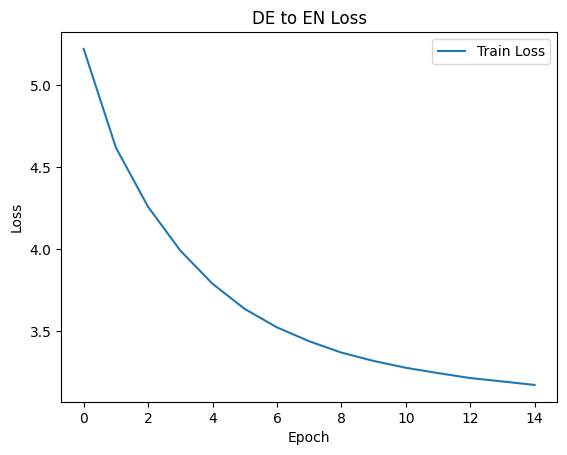

In [ ]:
plt.plot(de_en_history.history["loss"], label="Train Loss")
plt.title("DE to EN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

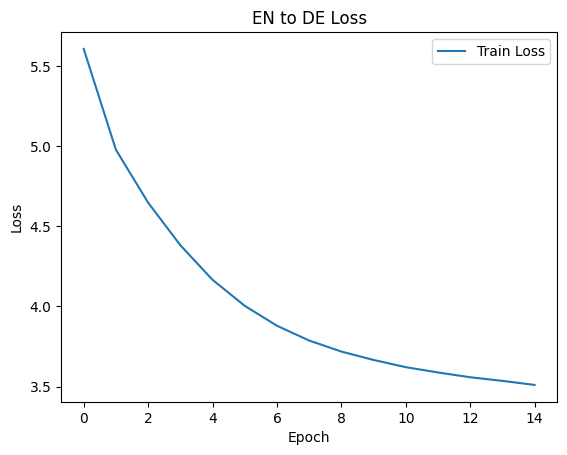

In [ ]:
plt.plot(en_de_history.history["loss"], label="Train Loss")
plt.title("EN to DE Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

# User Input / Model Prediction

Steps:

    -create list of sentences so I don't have to manually change each test sentence
    -input sentence(s)
    -vectorize input
    -predict input
    -decode prediction
        -how many positions to loop through
        -finds the index of the highest probability word (t)
        -converts index to a word
        -stop if model comes across end, empty string, or an unknown word
        -skip start token
    -add predicted words into a string, then use .strip to remove the trailing space at the end

## German to English

In [ ]:
# de_sentences = [
#     'Ich sehe',
#     'Ich sehe die Katze',
#     'Die Katze isst den Fisch',
#     'Ich spiele mit der Katze',
#     'Die Katze will spielen',
#     'Weil die Katze gegessen hat',
#     'Kann die Katze ein Nickerchen machen?',
#     'Die Katze hat einen Fisch für Abendbrot',
#     'Der Fisch wurde von die Katze gegessen',
#     'Die Schüssel der Katze'
# ]

https://lyricstranslate.com/en/stille-nacht-full-version-silent-night.html-0

In [ ]:
de_sentences = [
    "Stille Nacht! Heilige Nacht!",
    "Alles schläft, einsam wacht",
    "Nur das traute hochheilige Paar.",
    "Holder Knabe im lockigen Haar,",
    "Schlaf in himmlischer Ruh!",
    "Schlaf in himmlischer Ruh!",

    "Stille Nacht! Heilige Nacht!",
    "Gottes Sohn, o wie lacht",
    "Lieb aus deinem göttlichen Mund,",
    "Da uns schlägt die rettende Stund‘.",
    "Christ, in deiner Geburt!",
    "Christ, in deiner Geburt!",

    "Stille Nacht! Heilige Nacht!",
    "Die der Welt Heil gebracht,",
    "Aus des Himmels goldenen Höh‘n",
    "Uns der Gnaden Fülle lässt seh‘n",
    "Jesus, in Menschengestalt,",
    "Jesus, in Menschengestalt",

    "Stille Nacht! Heilige Nacht!",
    "Wo sich heute alle Macht",
    "Väterlicher Liebe ergoss",
    "Und als Bruder huldvoll umschloss.",
    "Jesus, die Völker der Welt,",
    "Jesus, die Völker der Welt.",

    "Stille Nacht! Heilige Nacht!",
    "Lange schon uns bedacht,",
    "Als der Herr vom Grimme befreit,",
    "In der Väter urgrauer Zeit",
    "Aller Welt Schonung verhieß,",
    "Aller Welt Schonung verhieß.",

    "Stille Nacht! Heilige Nacht!",
    "Hirten erst kundgemacht",
    "Durch der Engel Halleluja,",
    "Tönt es laut von ferne und nah:",
    "Christus, der Retter, ist da!",
    "Christus, der Retter ist da!"
]

In [ ]:
for de_sentence in de_sentences:
    de_sequence = de_vectorizer(np.array([de_sentence])).numpy()
    de_sequence = tf.keras.preprocessing.sequence.pad_sequences(de_sequence, maxlen=max_len - 1, padding="post", truncating="post")

    de_predictions = de_en_model.predict(de_sequence, verbose=0)
    de_result = []

    for t in range(de_predictions.shape[1]):
        token_idx = np.argmax(de_predictions[0, t, :])
        word = en_index_to_word[token_idx]

        if word in ["end", "<end>", "", "[UNK]"]:
            break

        if word != "<start>":
            de_result.append(word)

    de_translation = ""
    for word in de_result:
        de_translation = de_translation + word + " "

    print(f'{de_sentence} --> {de_translation.strip()}')

Stille Nacht! Heilige Nacht! --> beijing rain sets
Alles schläft, einsam wacht --> can in
Nur das traute hochheilige Paar. --> a the had the the a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a
Holder Knabe im lockigen Haar, --> 
Schlaf in himmlischer Ruh! --> 
Schlaf in himmlischer Ruh! --> 
Stille Nacht! Heilige Nacht! --> beijing rain sets
Gottes Sohn, o wie lacht --> of son still a
Lieb aus deinem göttlichen Mund, --> produces the his place mouth a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a
Da uns schlägt die rettende Stund‘. --> is us on the the
Christ, in deiner Geburt! --> 
Christ, in deiner Geburt! --> 
Stille Nacht! Heilige Nacht! --> beijing rain sets
Die der Welt Heil gebracht, --> the campaign glad return sugar a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a a

## English to German

do the same but with an english input (all in one cell as I have already explained what is happening with the german input model)

In [ ]:
# en_sentences = [
#     'I see',
#     'I see the cat',
#     'The cat ate the fish',
#     'I play with the cat',
#     'The cat wants to play',
#     'Because the cat ate',
#     'Can the cat take a nap?',
#     'The cat had a fish for dinner',
#     'The fish was eaten by the cat',
#     "The cat’s bowl"
# ]

https://lyricstranslate.com/en/stille-nacht-full-version-silent-night.html-0

In [ ]:
en_sentences = [
    "Silent Night! Holy Night!",
    "All is calm, all is bright",
    "Round yon godly tender pair.",
    "Holy infant with curly hair,",
    "Sleep in heavenly peace,",
    "Sleep in heavenly peace.",

    "Silent Night! Holy Night!",
    "Son of God, love's pure light",
    "Radiant beams from thy holy face,",
    "With the dawn of redeeming grace,",
    "Jesus, Lord at thy birth",
    "Jesus, Lord at thy birth.",

    "Silent Night! Holy Night!",
    "Brought the world gracious light,",
    "Down from heaven's golden height",
    "Comes to us the glorious sight:",
    "Jesus, as one of mankind,",
    "Jesus, as one of mankind.",

    "Silent Night! Holy Night!",
    "By his love, by his might",
    "God our Father us has graced,",
    "As a brother gently embraced",
    "Jesus, all nations on earth,",
    "Jesus, all nations on earth.",

    "Silent Night! Holy Night!",
    "Long ago, minding our plight",
    "God the world from misery freed,",
    "In the dark age of our fathers decreed:",
    "All the world redeemed,",
    "All the world redeemed.",

    "Silent Night! Holy Night!",
    "Shepherds first saw the sight",
    "Of angels singing alleluia",
    "Calling clearly near and far:",
    "Christ, the saviour is born,",
    "Christ the Saviour is born."
]

In [ ]:
for en_sentence in en_sentences:
    en_sequence  = en_vectorizer(np.array([en_sentence])).numpy()
    en_sequence  = tf.keras.preprocessing.sequence.pad_sequences(en_sequence, maxlen=max_len - 1, padding="post", truncating="post")

    en_predictions = en_de_model.predict(en_sequence, verbose=0)
    en_result = []

    for t in range(en_predictions.shape[1]):
        token_idx = np.argmax(en_predictions[0, t, :])
        word = de_index_to_word[token_idx]

        if word in ["end", "<end>", "", "[UNK]"]:
            break

        if word != "<start>":
            en_result.append(word)

    en_translation = ""
    for word in en_result:
        en_translation = en_translation + word + " "

    print(f'{en_sentence} --> {en_translation.strip()}')

Silent Night! Holy Night! --> 
All is calm, all is bright --> 
Round yon godly tender pair. --> 
Holy infant with curly hair, --> solchen februar reiseschecks bedeutungen tauschen
Sleep in heavenly peace, --> 
Sleep in heavenly peace. --> 
Silent Night! Holy Night! --> 
Son of God, love's pure light --> ich
Radiant beams from thy holy face, --> 
With the dawn of redeeming grace, --> reiseschecks entwicklung der
Jesus, Lord at thy birth --> fordert vergleichen einigen
Jesus, Lord at thy birth. --> fordert vergleichen einigen
Silent Night! Holy Night! --> 
Brought the world gracious light, --> und aussicht
Down from heaven's golden height --> körperliche entlehnt errichtet
Comes to us the glorious sight: --> tatsachen küchenschaben
Jesus, as one of mankind, --> fordert wie zustimmung verdanken
Jesus, as one of mankind. --> fordert wie zustimmung verdanken
Silent Night! Holy Night! --> 
By his love, by his might --> davongetragen schulden lieben 21 beurteilen lächerlich
God our Father us 